In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
df_index=pd.read_csv('/kaggle/input/datasets/surajpandey73/multipleregression/economic_index.csv')
df_index.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [8]:
df_index.drop(columns=['Unnamed: 0',"year","month"],axis=1,inplace=True)

KeyError: "['Unnamed: 0', 'year', 'month'] not found in axis"

In [ ]:
df_index

In [ ]:
# CHEKING FOR NULL VALUE
df_index.isnull().sum()

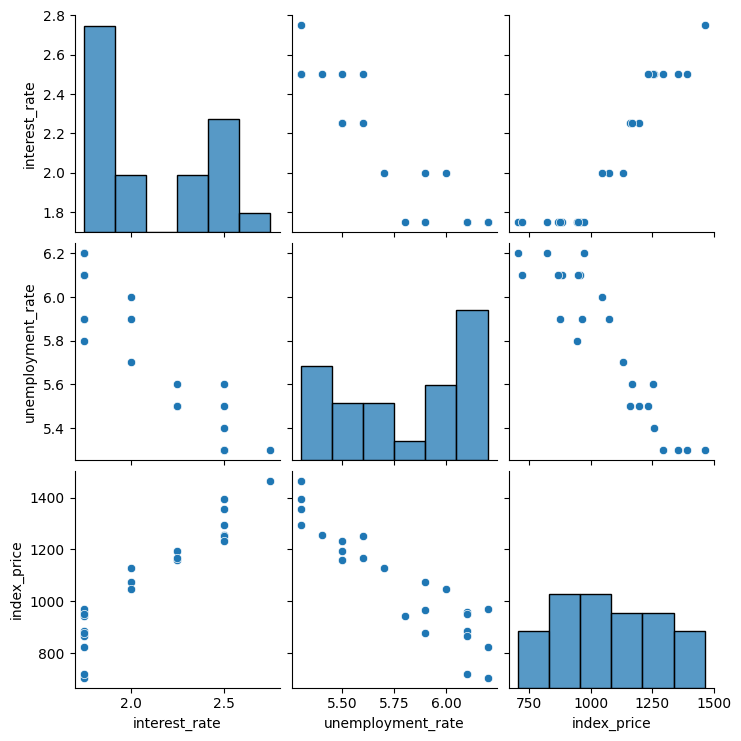

In [9]:
import seaborn as sns
sns.pairplot(df_index)

In [ ]:
df_index.corr()

Text(0, 0.5, 'Unemployment rate')

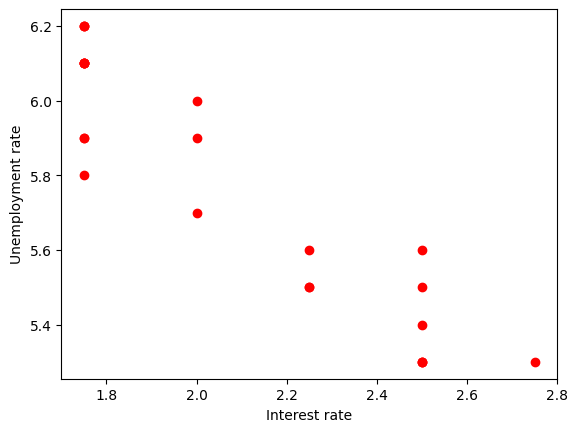

In [11]:
# VISUALIZE the data points more closely
plt.scatter(df_index['interest_rate'],df_index['unemployment_rate'],color='red')
plt.xlabel('Interest rate')
plt.ylabel('Unemployment rate')

In [24]:
# INDEPENDEN AND DEPENDEN FEATURE
X=df_index.iloc[:,:-1]
y=df_index.iloc[:,-1]

In [17]:
X.head()


,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4


In [18]:
y.head()

0    1464
1    1394
2    1357
3    1293
4    1256
Name: index_price, dtype: int64

In [26]:
# TRAIN TEST SPLIT
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [31]:
import seaborn as sns

<Axes: xlabel='interest_rate', ylabel='index_price'>

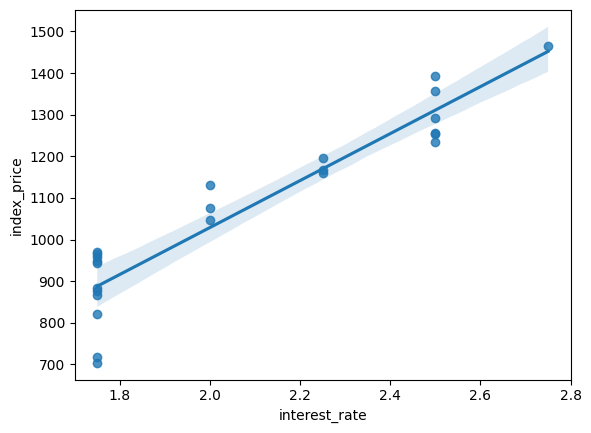

In [34]:
sns.regplot(x=df_index['interest_rate'],y=df_index['index_price'])

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

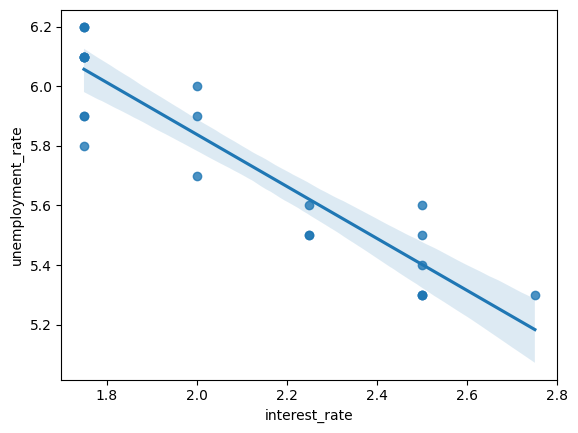

In [39]:
sns.regplot(x=df_index['interest_rate'],y=df_index['unemployment_rate'])

<Axes: xlabel='index_price', ylabel='unemployment_rate'>

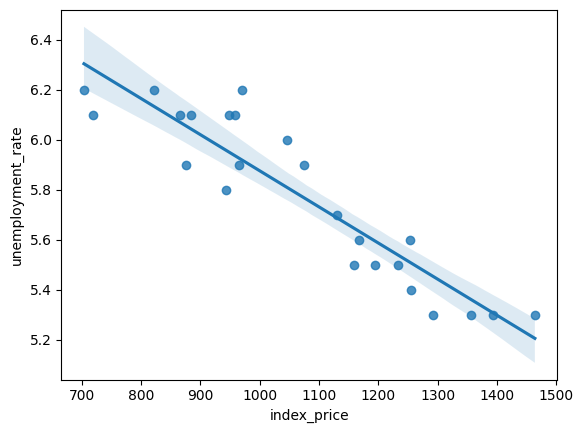

In [41]:
sns.regplot(x=df_index['index_price'],y=df_index['unemployment_rate'])

In [43]:
from sklearn.preprocessing import StandardScaler

In [47]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [48]:
X_train

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

In [49]:
from sklearn.linear_model import LinearRegression
regression=LinearRegression()

In [50]:
regression.fit(X_train,y_train)

LinearRegression()

In [54]:
from sklearn.model_selection import cross_val_score 
validation_score=cross_val_score(regression,X_train,y_train,scoring='neg_mean_squared_error',
cv=3)

In [55]:
np.mean(validation_score)

np.float64(-5914.828180162393)

In [57]:
# PREDICTION
y_pred=regression.predict(X_test)

In [58]:
y_pred

array([1204.22770398,  821.65051903, 1406.51300368,  857.70889608,
        994.90992298, 1168.16932693])

In [60]:
print("Actual values:", y_test)


Actual values: 8     1159
16     971
0     1464
18     884
11    1075
9     1167
Name: index_price, dtype: int64


In [61]:
print("Predicted values:", y_pred)

Predicted values: [1204.22770398  821.65051903 1406.51300368  857.70889608  994.90992298
 1168.16932693]


In [67]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)
print( "adjsted r2 :", 1 - (1-r2) * (len(y_test)-1) /
      (len(y_test)-X_test.shape[1]-1))

MSE: 5793.76288771258
MAE: 59.93578152323554
RMSE: 76.11677139574813
R2 Score: 0.8278978091457142
adjsted r2 : 0.713163015242857


In [ ]:
ASSUMPTIONS

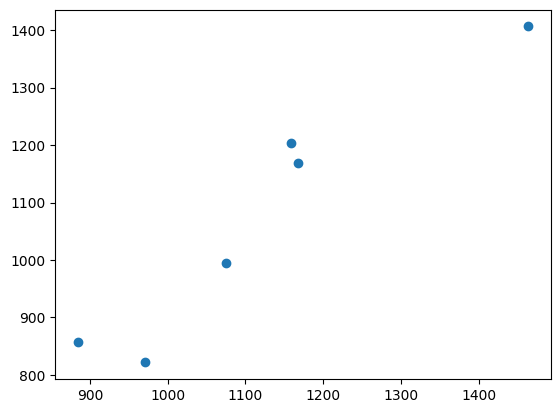

In [68]:
plt.scatter(y_test,y_pred)

In [69]:
residuals=y_test-y_pred
print(residuals)

8     -45.227704
16    149.349481
0      57.486996
18     26.291104
11     80.090077
9      -1.169327
Name: index_price, dtype: float64


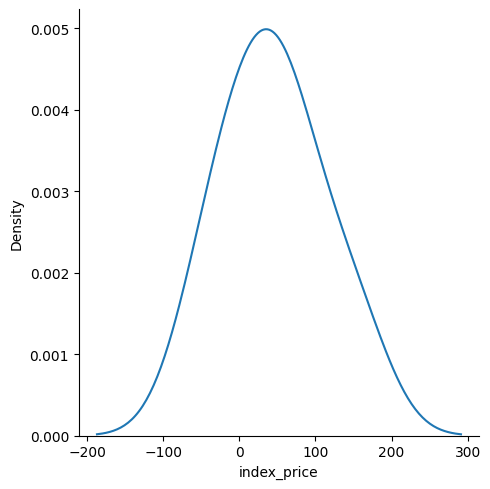

In [70]:
# plot this residuals
sns.displot(residuals,kind='kde')

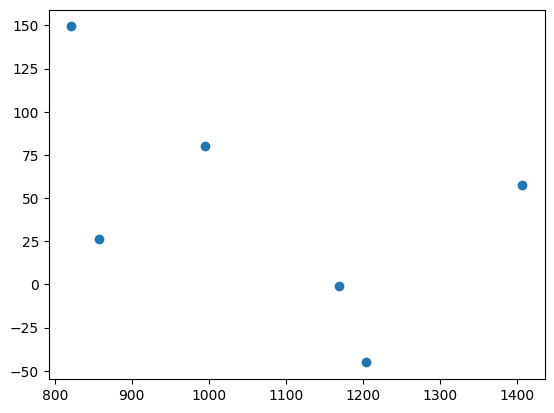

In [71]:
# SCATTER PLOT WRT PREDICTION AND RESIDUALS
plt.scatter(y_pred,residuals)

In [72]:
print(regression.coef_)

[  88.27275507 -116.25716066]


In [73]:
# OLS LINEAR REGRESSION
import statsmodels.api as sm
model=sm.OLS(y_train,X_train).fit()

In [74]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            index_price   R-squared (uncentered):                   0.035
Model:                            OLS   Adj. R-squared (uncentered):             -0.086
Method:                 Least Squares   F-statistic:                             0.2880
Date:                Thu, 15 Oct 2026   Prob (F-statistic):                       0.754
Time:                        21:18:33   Log-Likelihood:                         -150.85
No. Observations:                  18   AIC:                                      305.7
Df Residuals:                      16   BIC:                                      307.5
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            88.2728    658.295      0.134      0.895   -1307.250    1483.796
x2          -116.2572    658.295     -0.177      0.862   -1511.780    1279.266
==============================================================================
Omnibus:                        0.598   Durbin-Watson:                   0.007
Prob(Omnibus):                  0.741   Jarque-Bera (JB):                0.567
Skew:                          -0.361   Prob(JB):                        0.753
Kurtosis:                       2.517   Cond. No.                         4.78
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [75]:
print("Intercept:", regression.intercept_)
print("Coefficients:", regression.coef_)

Intercept: 1053.4444444444443
Coefficients: [  88.27275507 -116.25716066]
